In [8]:
import dezero as dz
import dezero.functions as F
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def linear_simple(x, W, b=None):
    x, W = dz.as_variables(x, W)
    t = F.matmul(x, W)
    if b is None:
        return t

    y = t + b
    t.data = None
    return y

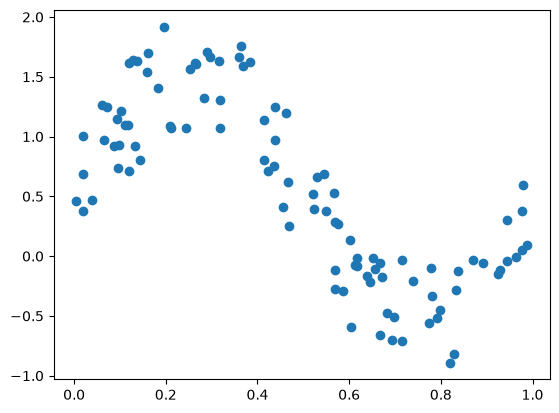

In [5]:
%matplotlib inline
np.random.seed(0)
x = np.random.rand(100, 1)
y = np.sin(2 * np.pi * x) + np.random.rand(100, 1)

plt.plot(x, y, 'o')

In [38]:
import numpy as np
from dezero import Variable, as_variable
import dezero.functions as F
from tqdm import tqdm

np.random.seed(0)
x = np.random.rand(100, 1)
y = np.sin(2 * np.pi * x) + np.random.rand(100, 1)

# init weights
I, H, O = 1, 10, 1 # input, hidden, output
W1 = Variable(0.01 * np.random.randn(I, H))
b1 = Variable(np.zeros(H))
W2 = Variable(0.01 * np.random.randn(H, O))
b2 = Variable(np.zeros(O))

# predict NNW
def predict(x):
    _y = F.linear(x, W1, b1)
    _y = F.sigmoid(_y)
    _y = F.linear(_y, W2, b2)
    return _y

# optimizer
lr = 0.2
iters = 10000

losses = []
for step in tqdm(range(iters), "learning two layers"):
    y_pred = predict(x)
    loss = F.mean_squared_error(y, y_pred)

    W1.cleargrad()
    b1.cleargrad()
    W2.cleargrad()
    b2.cleargrad()
    loss.backward()

    W1.data -= lr * W1.grad.data
    b1.data -= lr * b1.grad.data
    W2.data -= lr * W2.grad.data
    b2.data -= lr * b2.grad.data
    
    losses.append(float(loss.data.squeeze()))

learning two layers: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:03<00:00, 2866.33it/s]


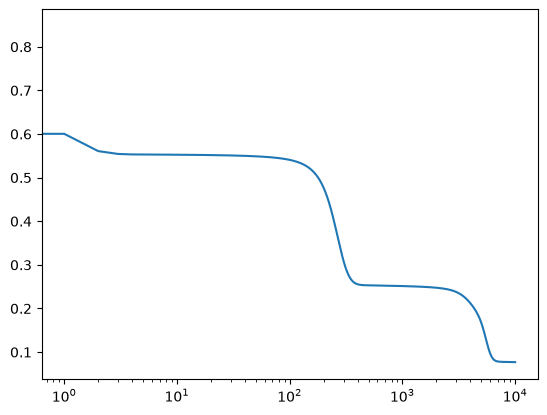

In [39]:
%matplotlib inline
plt.plot(range(iters), losses)
plt.xscale("log")

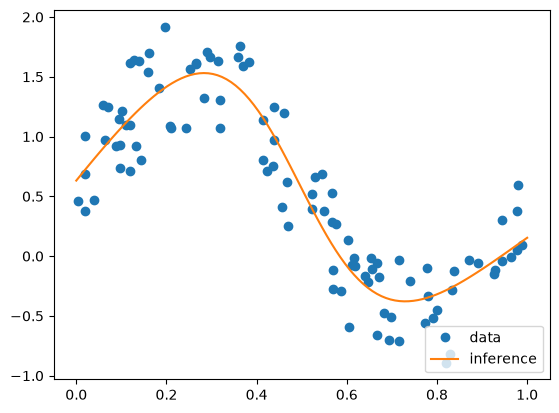

In [45]:
_x = np.linspace(0, 1, 100).reshape(100, 1)
with dz.no_grad():
    _y_pred = predict(_x).data
plt.plot(x.squeeze(), y.squeeze(), 'o', label="data")
plt.plot(_x.squeeze(), _y_pred.squeeze(), label="inference")
plt.legend(loc='lower right')